In [1]:
import pandas as pd, numpy as np
import seaborn as sns, matplotlib.pyplot as plt
sns.set_theme(style="whitegrid")

df = pd.read_csv("pakistan_social_media_posts.csv")
print(df.shape)
df.head()

(3030, 17)


,post_id,timestamp,platform,brand_category,content_type,topic,caption,hashtags,language,city,audience_segment,followers_count,verified,likes,shares,comments,sentiment
0,PK01396,2024-05-11 19:26,TikTok,Telecom,Text Post,Sales & Offers,Aaj ka menu aur timings dekhein,#Discount #MegaSale #BlackFriday,Roman Urdu,Lahore,Gen Z (18-24),117502.0,False,1145,101,160,Neutral
1,PK02390,2024-10-11 21:30,Facebook,Education,Carousel,Humor & Memes,Details in the link below,#DesiMemes #Relatable #PakistaniHumor #Pakistan,Mixed (Urdu-English),Faisalabad,Small Business Owners,3335.0,False,141,22,4,Neutral
2,PK01349,2024-06-01 18:24,Instagram,Electronics,Image Post,Sales & Offers,"Prices again up, kya hoga?",#FlashSale #MegaSale,English,Lahore,Small Business Owners,84477.0,False,1006,75,287,Negative
3,PK01618,2024-11-18 21:58,Instagram,Electronics,Short Video/Reel,Food,Delivery delay ke liye maazrat,#ChaiTime #Pakistan,Roman Urdu,Lahore,Students,1070.0,False,84,15,17,Negative
4,PK01936,2024-01-21 23:53,TikTok,Electronics,Short Video/Reel,Cricket & PSL,Delivery delay ke liye maazrat,#PakistanCricket #PSL #Pakistan,Roman Urdu,Islamabad,Parents (35-50),203777.0,False,14950,2144,1318,Negative


In [15]:
print(q5_day.sort_values(ascending=False).round(1))
print(q5_hour.head(5).round(1))

day_of_week
Friday       34.4
Sunday       30.0
Saturday     29.3
Thursday     28.7
Monday       25.8
Wednesday    25.2
Tuesday      24.9
Name: engagement_rate, dtype: float64
hour
20    38.8
22    38.6
23    38.2
21    38.1
13    32.5
Name: engagement_rate, dtype: float64


In [2]:
df.info()
print("Missing:\n", df.isna().sum())
print("Duplicates:", df.duplicated().sum())
print("Negative likes:", (df["likes"] < 0).sum())
print(df["platform"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3030 entries, 0 to 3029
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   post_id           3030 non-null   object 
 1   timestamp         3030 non-null   object 
 2   platform          3030 non-null   object 
 3   brand_category    3030 non-null   object 
 4   content_type      3030 non-null   object 
 5   topic             3030 non-null   object 
 6   caption           3030 non-null   object 
 7   hashtags          2969 non-null   object 
 8   language          3030 non-null   object 
 9   city              3030 non-null   object 
 10  audience_segment  3030 non-null   object 
 11  followers_count   3005 non-null   float64
 12  verified          3030 non-null   bool   
 13  likes             3030 non-null   int64  
 14  shares            3030 non-null   int64  
 15  comments          3030 non-null   int64  
 16  sentiment         3030 non-null   object 


In [3]:
df = df.drop_duplicates()

# platform ke naam theek karo (tiktok -> TikTok)
fix = {"tiktok":"TikTok","facebook":"Facebook","instagram":"Instagram",
       "youtube":"YouTube","x (twitter)":"X (Twitter)"}
df["platform"] = df["platform"].str.strip().str.lower().map(fix)

df["likes"] = df["likes"].abs()
df["timestamp"] = pd.to_datetime(df["timestamp"])
df["hashtags"] = df["hashtags"].fillna("")
df = df.dropna(subset=["followers_count"])   # followers ke baghair rate nahi nikalta

print(df.shape)
df["platform"].value_counts()

(2975, 17)


platform
TikTok         766
Facebook       706
Instagram      703
YouTube        460
X (Twitter)    340
Name: count, dtype: int64

In [4]:
df["total_engagement"] = df["likes"] + df["shares"] + df["comments"]
df["engagement_rate"] = df["total_engagement"] / df["followers_count"] * 1000
df["day_of_week"] = df["timestamp"].dt.day_name()
df["hour"] = df["timestamp"].dt.hour
df["hashtag_count"] = df["hashtags"].str.count("#")
df["follower_tier"] = pd.cut(df["followers_count"], [0, 1e4, 5e4, 2e5, np.inf],
                             labels=["Nano","Micro","Mid","Macro"])
df[["platform","total_engagement","engagement_rate","day_of_week","hour"]].head()

,platform,total_engagement,engagement_rate,day_of_week,hour
0,TikTok,1406,11.965754,Saturday,19
1,Facebook,167,50.074963,Friday,21
2,Instagram,1368,16.193757,Saturday,18
3,Instagram,116,108.411215,Monday,21
4,TikTok,18412,90.353671,Sunday,23


,median,mean,count
platform,,,
TikTok,43.4,60.6,766
Facebook,30.2,41.5,706
Instagram,25.8,35.8,703
YouTube,20.5,28.1,460
X (Twitter),14.7,21.4,340


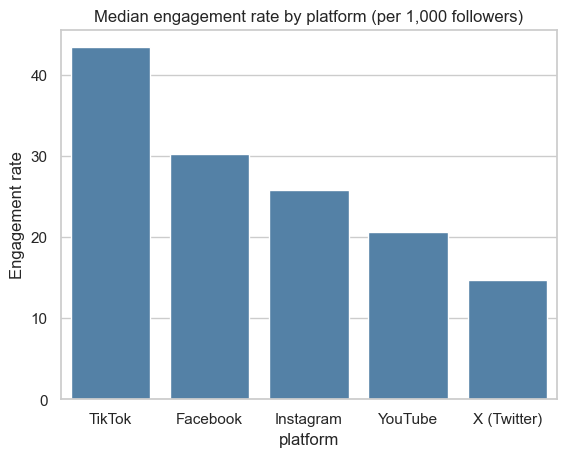

In [5]:
q1 = df.groupby("platform")["engagement_rate"].agg(["median","mean","count"]).sort_values("median", ascending=False)
display(q1.round(1))
sns.barplot(data=q1.reset_index(), x="platform", y="median", color="steelblue")
plt.title("Median engagement rate by platform (per 1,000 followers)")
plt.ylabel("Engagement rate"); plt.show()

,median,count
content_type,,
Short Video/Reel,42.1,902
Live Stream,34.3,204
Poll/Question,31.2,330
Carousel,28.0,352
Image Post,24.0,762
Text Post,14.2,425


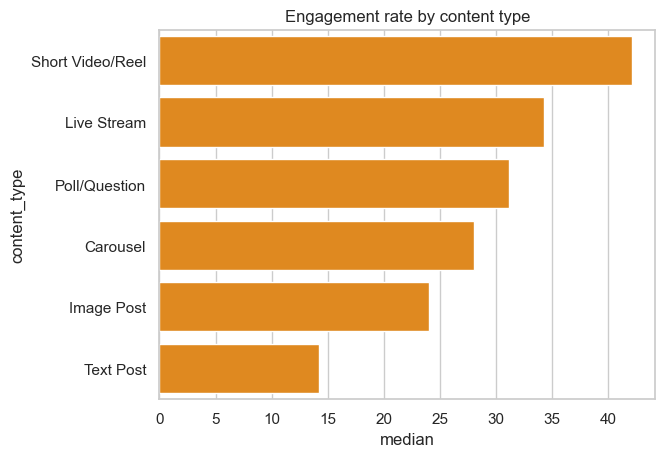

In [6]:
q2 = df.groupby("content_type")["engagement_rate"].agg(["median","count"]).sort_values("median", ascending=False)
display(q2.round(1))
sns.barplot(data=q2.reset_index(), y="content_type", x="median", color="darkorange")
plt.title("Engagement rate by content type"); plt.show()

,median,count
topic,,
Cricket & PSL,39.8,418
Ramadan & Eid,36.5,359
Humor & Memes,33.9,368
Independence Day,33.1,169
Fashion & Weddings,28.7,381
Food,26.4,355
Sales & Offers,21.8,383
Tech & Gadgets,20.4,267
Education & Career,17.2,275


,median,count
tag,,
#PakistanCricket,43.2,213
#CricketFever,42.6,206
#PSL,41.5,197
#Ramadan,41.2,174
#EidSale,40.1,179
#JashneAzadi,38.4,102
#PakistanZindabad,38.3,111
#BabarAzam,38.2,187
#EidMubarak,37.8,180


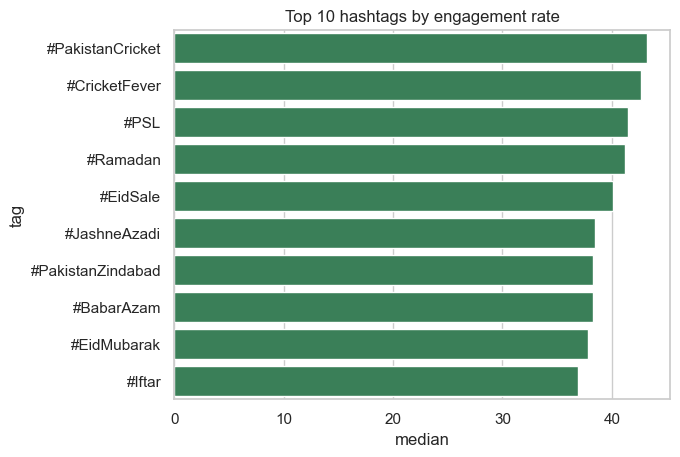

In [7]:
q3a = df.groupby("topic")["engagement_rate"].agg(["median","count"]).sort_values("median", ascending=False)
display(q3a.round(1))

tags = df.assign(tag=df["hashtags"].str.findall(r"#\w+")).explode("tag").dropna(subset=["tag"])
q3b = (tags.groupby("tag")["engagement_rate"].agg(["median","count"])
           .query("count >= 20").sort_values("median", ascending=False).head(10))
display(q3b.round(1))
sns.barplot(data=q3b.reset_index(), y="tag", x="median", color="seagreen")
plt.title("Top 10 hashtags by engagement rate"); plt.show()

,median,count
sentiment,,
Negative,27.1,562
Neutral,21.7,940
Positive,33.6,1473


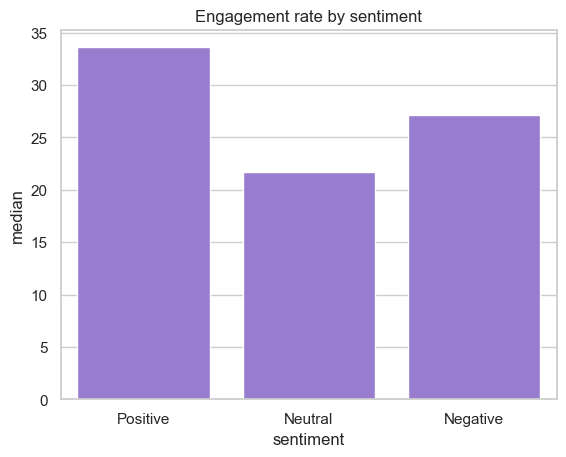

In [8]:
q4 = df.groupby("sentiment")["engagement_rate"].agg(["median","count"])
display(q4.round(1))
sns.barplot(data=q4.reset_index(), x="sentiment", y="median",
            order=["Positive","Neutral","Negative"], color="mediumpurple")
plt.title("Engagement rate by sentiment"); plt.show()

day_of_week
Monday       25.8
Tuesday      24.9
Wednesday    25.2
Thursday     28.7
Friday       34.4
Saturday     29.3
Sunday       30.0
Name: engagement_rate, dtype: float64

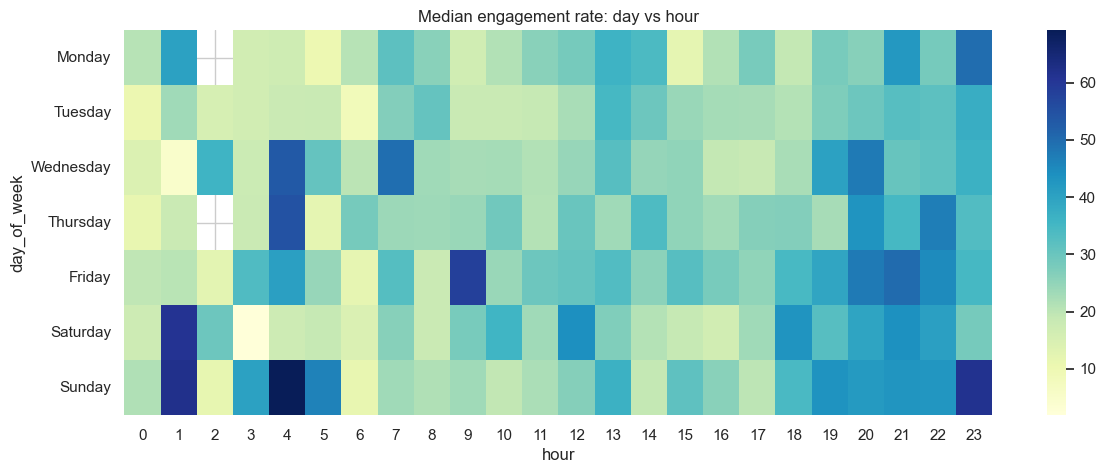

Top 5 hours:
 hour
20    38.8
22    38.6
23    38.2
21    38.1
13    32.5
Name: engagement_rate, dtype: float64


In [9]:
order = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
q5_day = df.groupby("day_of_week")["engagement_rate"].median().reindex(order)
display(q5_day.round(1))

plt.figure(figsize=(14,5))
heat = df.pivot_table(index="day_of_week", columns="hour", values="engagement_rate", aggfunc="median").reindex(order)
sns.heatmap(heat, cmap="YlGnBu")
plt.title("Median engagement rate: day vs hour"); plt.show()

q5_hour = df.groupby("hour")["engagement_rate"].median().sort_values(ascending=False)
print("Top 5 hours:\n", q5_hour.head(5).round(1))


--- audience_segment ---


,median,count
audience_segment,,
Gen Z (18-24),37.1,823
Students,31.5,629
Young Professionals (25-34),27.6,764
Parents (35-50),21.3,409
Small Business Owners,20.2,350



--- city ---


,median,count
city,,
Lahore,32.0,734
Karachi,29.6,812
Islamabad,28.5,382
Rawalpindi,25.8,214
Peshawar,24.6,256
Faisalabad,23.8,201
Multan,23.0,295
Quetta,20.8,81



--- language ---


,median,count
language,,
Mixed (Urdu-English),31.1,846
Roman Urdu,29.7,994
Urdu,29.3,398
English,22.5,737



--- follower_tier ---


,median,count
follower_tier,,
Nano,33.5,481
Micro,27.9,1319
Mid,26.1,913
Macro,25.8,262



--- verified ---


,median,count
verified,,
True,29.1,653
False,27.5,2322


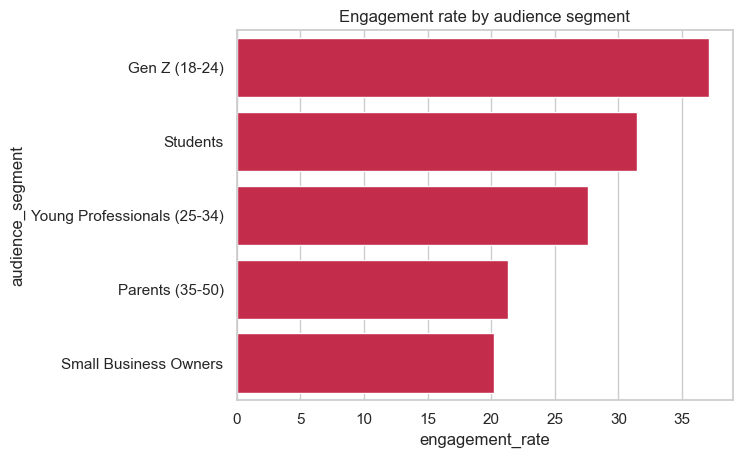

In [10]:
for col in ["audience_segment","city","language","follower_tier","verified"]:
    t = df.groupby(col, observed=True)["engagement_rate"].agg(["median","count"]).sort_values("median", ascending=False)
    print(f"\n--- {col} ---"); display(t.round(1))

sns.barplot(data=df.groupby("audience_segment")["engagement_rate"].median().sort_values(ascending=False).reset_index(),
            y="audience_segment", x="engagement_rate", color="crimson")
plt.title("Engagement rate by audience segment"); plt.show()

In [11]:
best = lambda col: df.groupby(col, observed=True)["engagement_rate"].median().idxmax()
top_tags = ", ".join(q3b.index[:3])
summary = f"""
Best platform: {best('platform')}
Best content type: {best('content_type')}
Best topic: {best('topic')}
Best hashtags: {top_tags}
Best sentiment: {best('sentiment')}
Best day: {best('day_of_week')}
Best hour: {q5_hour.index[0]}:00
Best audience segment: {best('audience_segment')}
Best city: {best('city')}
Best language: {best('language')}
"""
print(summary)


Best platform: TikTok
Best content type: Short Video/Reel
Best topic: Cricket & PSL
Best hashtags: #PakistanCricket, #CricketFever, #PSL
Best sentiment: Positive
Best day: Friday
Best hour: 20:00
Best audience segment: Gen Z (18-24)
Best city: Lahore
Best language: Mixed (Urdu-English)



In [12]:
df.to_csv("pakistan_social_media_clean.csv", index=False)

In [13]:
print(q5_day.sort_values(ascending=False).round(1))
print(q5_hour.head(5).round(1))

day_of_week
Friday       34.4
Sunday       30.0
Saturday     29.3
Thursday     28.7
Monday       25.8
Wednesday    25.2
Tuesday      24.9
Name: engagement_rate, dtype: float64
hour
20    38.8
22    38.6
23    38.2
21    38.1
13    32.5
Name: engagement_rate, dtype: float64


In [14]:
fashion = df[df["brand_category"] == "Fashion & Lifestyle"]
print(len(fashion))
print(fashion.groupby("topic")["engagement_rate"].agg(["median","count"])
      .sort_values("median", ascending=False).round(1))
print(fashion.groupby("platform")["engagement_rate"].median().sort_values(ascending=False).round(1))
print(fashion.groupby("content_type")["engagement_rate"].median().sort_values(ascending=False).round(1))

431
                    median  count
topic                            
Cricket & PSL         48.3     56
Ramadan & Eid         37.6     63
Independence Day      33.3     28
Humor & Memes         32.4     51
Food                  29.6     36
Fashion & Weddings    28.8     47
Sales & Offers        21.0     64
Tech & Gadgets        19.1     43
Education & Career    17.2     43
platform
TikTok         39.2
Facebook       28.0
Instagram      25.2
YouTube        22.7
X (Twitter)    18.6
Name: engagement_rate, dtype: float64
content_type
Short Video/Reel    42.4
Live Stream         40.3
Poll/Question       27.8
Carousel            26.1
Image Post          22.4
Text Post           15.6
Name: engagement_rate, dtype: float64
